# 3 · PM decisions: a suspicious model, readable rules, three models, fairness

**What you practise (from the decision-tree lecture):**
- **Activity C:** find the product failure (a column the model should never see).
- Turning a tree into **rules** dispatch can read, and spotting a rule you shouldn't trust.
- **LR vs KNN vs tree** on the same orders.
- Checking whether the model works **equally well for different groups**.
- Prediction ≠ cause, and writing your **recommendation** for Lina.

> **How this notebook works**
> - Run the cells **from top to bottom** with `Shift + Enter`.
> - ▶️ **Run** cells work as they are.
> - ✏️ **Your turn** cells contain `___` (three underscores). Replace each `___` with your answer, then run the cell.
> - ✅ **Check** cells tell you whether you got it right. If a check fails, read the hint, fix the cell above and run both again.
> - 🧠 **Think** cells ask a PM question. Double-click the answer cell below it and write 1–3 sentences.
> - If you see `NameError: name '___' is not defined`, a blank is still empty.
> - Stuck? The `solutions/` folder has the same notebook, solved.

## Step 0 · Load, prepare and split (same as notebook 2)

> In this notebook we **reuse the test orders** to illustrate several PM checks. That's fine for learning; in a real project each new decision would be made on validation data, and the test set used once at the very end.

In [1]:
# ▶️ Run: load the tools and the data, and prepare the inputs exactly like notebook 1
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay

orders = pd.read_csv("../data/quickcart_orders.csv")
features = ["order_hour", "weekday", "distance_km", "items_count", "basket_value_eur", "weather",
            "traffic_level", "store_queue", "courier_experience_months", "vehicle",
            "is_premium_customer", "promo_used", "customer_previous_orders"]
X = pd.get_dummies(orders[features], dtype=int)
y = orders["late"]
print("X:", X.shape, "| late share:", round(y.mean(), 3))

X: (3000, 23) | late share: 0.248


In [2]:
# ▶️ Run: the same honest split as notebook 2 (75% to learn, 25% kept aside as the final exam)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("train:", X_train.shape[0], "orders | test:", X_test.shape[0], "orders, of which late:", y_test.sum())

train: 2250 orders | test: 750 orders, of which late: 186


## Step 1 · Activity C: Jonas's "amazing" model

Jonas, the data scientist, says: *"I used **all** the columns, including `order_id` and `customer_rating`. Look at this score!"*

In [3]:
# ▶️ Run: Jonas's model (same split, same depth 4, but two extra columns)
X_jonas = X.assign(order_id=orders["order_id"], customer_rating=orders["customer_rating"])
Xj_train, Xj_test = X_jonas.loc[X_train.index], X_jonas.loc[X_test.index]
jonas_tree = DecisionTreeClassifier(max_depth=4, random_state=42).fit(Xj_train, y_train)
jonas_auc = roc_auc_score(y_test, jonas_tree.predict_proba(Xj_test)[:, 1])
print("Jonas's test AUC:", round(jonas_auc, 3), "  (our depth-4 tree: 0.770)")

Jonas's test AUC: 0.955   (our depth-4 tree: 0.770)


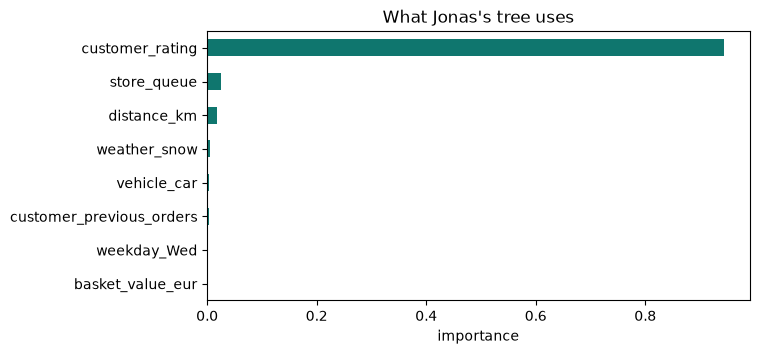

customer_rating    0.943
store_queue        0.026
distance_km        0.019
weather_snow       0.005
vehicle_car        0.004
dtype: float64

In [4]:
# ▶️ Run: which columns does Jonas's tree rely on? (feature importance = share of the mixing reduction)
importance = pd.Series(jonas_tree.feature_importances_, index=X_jonas.columns).sort_values(ascending=False)
importance.head(8).plot.barh(figsize=(7, 3.5), color="#0f766e").invert_yaxis()
plt.title("What Jonas's tree uses"); plt.xlabel("importance"); plt.show()
importance.head(5).round(3)

In [5]:
# ✏️ Your turn: which column is suspicious? (write the column name)
suspicious_column = "customer_rating"

In [6]:
# ✅ Check
assert suspicious_column.strip() == "customer_rating", "Look at the top bar."
print("✅ customer_rating does 94% of the work. Average rating: late orders",
      round(orders.loc[orders.late == 1, "customer_rating"].mean(), 2), "| on-time orders",
      round(orders.loc[orders.late == 0, "customer_rating"].mean(), 2))

✅ customer_rating does 94% of the work. Average rating: late orders 1.77 | on-time orders 4.41


🧠 **Think:** *when* does QuickCart know the customer's rating? Can the model use it when an order is placed? What is this mistake called?

**✍️ Sample answer:** The customer rates the order **after** it was delivered, so the rating is not available when we need the prediction (at order time). Late orders get bad ratings *because* they were late. The model is reading the answer. This is **data leakage**: in testing it looks brilliant (0.955), in production the column is empty and the model fails.

In [7]:
# ✏️ Your turn: retrain WITHOUT the leaky column. Which column do we drop?
honest_train = Xj_train.drop(columns=["customer_rating"])
honest_test = Xj_test.drop(columns=["customer_rating"])
honest_tree = DecisionTreeClassifier(max_depth=4, random_state=42).fit(honest_train, y_train)
honest_auc = roc_auc_score(y_test, honest_tree.predict_proba(honest_test)[:, 1])
print("Test AUC without the leak:", round(honest_auc, 3))
print("Importance of order_id:", round(pd.Series(honest_tree.feature_importances_, index=honest_train.columns)["order_id"], 3))

Test AUC without the leak: 0.77
Importance of order_id: 0.009


🧠 **Think:** `order_id` got a small importance. Should an order number be a model input? Why or why not?

**✍️ Sample answer:** No. An order number is a label for bookkeeping, not information about the order. Any pattern the tree finds in it is accidental (or reflects how IDs happen to be assigned, e.g. over time) and won't hold for new orders. Like an interview date in a survey: it describes *when/how* data was recorded, not the thing we predict. Drop identifiers. (Tree importance tends to favour columns with many different values, like IDs, which is why it got any importance at all.) Our final model (test AUC 0.770) excludes both `order_id` and `customer_rating`.

## Step 2 · Rules dispatch can read

A depth-3 tree has at most 8 routes. `export_text` prints them. `weights: [on time, late]` = how many training orders ended there.

In [8]:
# ▶️ Run: the rules of a depth-3 tree
rule_tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print(export_text(rule_tree, feature_names=list(X_train.columns), show_weights=True))

|--- distance_km <= 6.05
|   |--- store_queue <= 10.50
|   |   |--- weather_clear <= 0.50
|   |   |   |--- weights: [377.00, 129.00] class: 0
|   |   |--- weather_clear >  0.50
|   |   |   |--- weights: [916.00, 71.00] class: 0
|   |--- store_queue >  10.50
|   |   |--- courier_experience_months <= 2.50
|   |   |   |--- weights: [10.00, 33.00] class: 1
|   |   |--- courier_experience_months >  2.50
|   |   |   |--- weights: [156.00, 86.00] class: 0
|--- distance_km >  6.05
|   |--- store_queue <= 10.50
|   |   |--- vehicle_bike <= 0.50
|   |   |   |--- weights: [171.00, 113.00] class: 0
|   |   |--- vehicle_bike >  0.50
|   |   |   |--- weights: [46.00, 68.00] class: 1
|   |--- store_queue >  10.50
|   |   |--- basket_value_eur <= 93.85
|   |   |   |--- weights: [13.00, 58.00] class: 1
|   |   |--- basket_value_eur >  93.85
|   |   |   |--- weights: [3.00, 0.00] class: 0



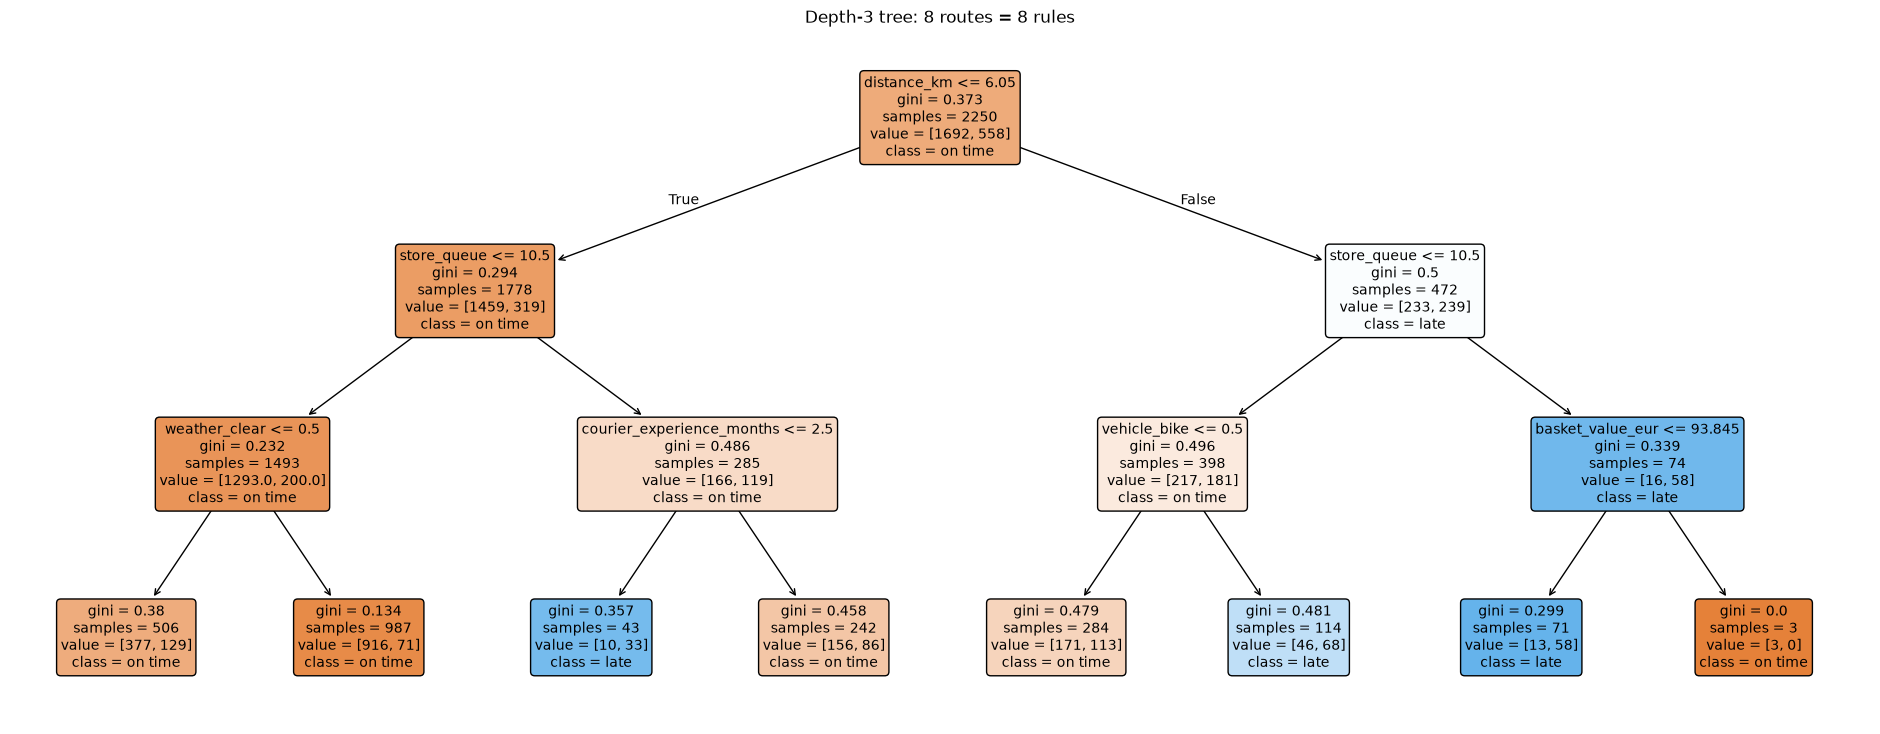

In [9]:
# ▶️ Run: the same depth-3 tree as a picture. Find the tiny leaf on the far right (samples = 3)
plt.figure(figsize=(24, 9))
plot_tree(rule_tree, feature_names=list(X_train.columns), class_names=["on time", "late"],
          filled=True, rounded=True, fontsize=10)
plt.title("Depth-3 tree: 8 routes = 8 rules")
plt.show()

In [10]:
# ▶️ Run: every leaf, sorted by late share (leaf numbers are scikit-learn's internal IDs)
leaves = pd.DataFrame({"leaf": rule_tree.apply(X_train), "late": y_train.values})
leaves.groupby("leaf")["late"].agg(late_share="mean", orders="size").sort_values("late_share", ascending=False).round(3)

,late_share,orders
leaf,,
13,0.817,71
6,0.767,43
11,0.596,114
10,0.398,284
7,0.355,242
3,0.255,506
4,0.072,987
14,0.000,3


In [11]:
# ✏️ Your turn: the riskiest leaf has a late share of about 82% (71 orders).
# Read its route in the rules above and fill in the three numbers/words.
riskiest_rule = "distance_km > 6.05 AND store_queue > 10.5 AND basket_value_eur <= 93.85"
print(riskiest_rule)

distance_km > 6.05 AND store_queue > 10.5 AND basket_value_eur <= 93.85


In [12]:
# ✅ Check
assert "___" not in riskiest_rule, "There is still a blank in your rule."
assert all(n in riskiest_rule for n in ["6.05", "10.5", "93.85"]), "Read the numbers on the route to the leaf with 58 late / 13 on time."
print("✅ Correct: far away AND busy store AND basket up to €93.85 → 82% of 71 past orders were late.")

✅ Correct: far away AND busy store AND basket up to €93.85 → 82% of 71 past orders were late.


🧠 **Think:** one leaf says *"far away, busy store, basket above €93.85 → 0% late"*. Look at how many orders it is based on. Would you put this rule on the dispatch screen? Which knob prevents it?

**✍️ Sample answer:** No. It is based on only **3** training orders (weights [3, 0]): far too few to believe that big baskets are never late; it's most likely chance. `min_samples_leaf` (e.g. 50) forbids leaves this small. Before showing rules to stakeholders, always check how many orders support each rule.

## Step 3 · LR vs KNN vs tree on the same 750 orders

Logistic regression and KNN need **scaled** inputs; `make_pipeline` scales inside the model so we can't forget it.

**Fair comparison:** different models spread their scores differently, so the same threshold makes them flag different numbers of orders. We let **each model flag the same number of orders** (its riskiest 151, like our policy, and its riskiest 200, dispatch's maximum) and count how many late orders each one catches.

In [13]:
# ✏️ Your turn: KNN looks at the 25 most similar past orders. Fill in the number of neighbours.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
    "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=42),
}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    s = model.predict_proba(X_test)[:, 1]
    riskiest = np.argsort(-s, kind="stable")          # test orders sorted from highest to lowest score
    rows.append({"model": name, "test AUC": round(roc_auc_score(y_test, s), 3),
                 "late caught in top 151": y_test.values[riskiest[:151]].sum(),
                 "late caught in top 200": y_test.values[riskiest[:200]].sum()})
comparison = pd.DataFrame(rows)
comparison

,model,test AUC,late caught in top 151,late caught in top 200
0,Logistic regression,0.735,70,86
1,KNN,0.665,68,83
2,Decision tree (depth 4),0.770,87,98


🧠 **Think:** which model would you recommend to Lina, considering ranking quality (AUC), recall, and that dispatch must understand *why* an order is flagged?

**✍️ Sample answer:** The depth-4 tree: best ranking (AUC 0.770 vs 0.735 LR and 0.665 KNN) and with the same number of flags it catches the most late orders (top 151: 87 vs 70 LR and 68 KNN; top 200: 98 vs 86 and 83, out of 186). It also explains each flag as a short route ("far + busy store"). Lateness here comes from combinations (far **and** bike, busy store **and** new courier) that a tree captures naturally and a single straight-line model doesn't. KNN is worst and hardest to explain ("similar to 25 past orders"). Caveat: one split of 750 orders; differences of 0.01–0.03 could change with another split.

## Step 4 · Does the model work equally well for everyone?

A model can be good *on average* and still fail a group. Check **recall per group**: of the late orders in each group, how many did the policy flag? We look at our policy (threshold 0.4) and, for comparison, at 0.3.

In [14]:
# ▶️ Run: attach the final tree's scores to the test orders
final_tree = models["Decision tree (depth 4)"]
test_orders = orders.loc[X_test.index].copy()
test_orders["score"] = final_tree.predict_proba(X_test)[:, 1]
test_orders["flag"] = (test_orders["score"] >= 0.4).astype(int)      # our policy from notebook 2
test_orders["flag_0.3"] = (test_orders["score"] >= 0.3).astype(int)  # a lower threshold, for comparison
test_orders[["distance_km", "weather", "vehicle", "late", "score", "flag", "flag_0.3"]].head()

,distance_km,weather,vehicle,late,score,flag,flag_0.3
1767,3.8,clear,scooter,0,0.055762,0,0
2937,5.9,clear,scooter,0,0.555556,1,1
1458,2.6,clear,bike,0,0.055762,0,0
25,2.9,rain,scooter,0,0.217494,0,0
2885,1.9,clear,bike,0,0.055762,0,0


In [15]:
# ✏️ Your turn: recall per vehicle type. Which column do we group by?
late_only = test_orders[test_orders["late"] == 1]
late_only.groupby("vehicle")[["flag", "flag_0.3"]].mean().round(2).assign(late_orders=late_only.groupby("vehicle").size())

,flag,flag_0.3,late_orders
vehicle,,,
bike,0.49,0.67,86
car,0.45,0.78,40
scooter,0.45,0.72,60


🧠 **Think:** the table shows recall per vehicle at our policy (`flag`, 0.4) and at 0.3. At 0.4 the groups look similar; at 0.3, late **bike** deliveries are caught less often (67%) than late **car** deliveries (78%). What does that teach you, and what would you check before launch? (Hint: also look at how many late orders each group has.)

**✍️ Sample answer:** Group results depend on the threshold, so fairness must be checked **at the threshold we actually ship**: at 0.4 recall is similar (bike 0.49, car 0.45, scooter 0.45); at 0.3 bike customers would get help less often than car customers. The groups are small (86 bike, 40 car, 60 scooter late orders), so gaps of a few points can be chance: check on more data or several splits. Also compare false alarms (precision) per group, not only recall. Before launch: report per-group results, agree on an acceptable gap, and re-check after every threshold change. Also: if courier columns (experience, vehicle) were ever used to *judge couriers*, that would be a different, sensitive use of the model; keep the purpose clear.

## Step 5 · Prediction ≠ cause

The tree says: *far + bike → often late.* Lina's idea: **"Ban bikes for orders over 6 km. Problem solved!"**

🧠 **Think:** does the model prove that switching to a car prevents lateness? What evidence would you want first?

**✍️ Sample answer:** No. The model shows that far bike orders *were* late more often in the past (a correlation in historical data), not that changing the vehicle *causes* on-time delivery. Bike orders may differ in other ways (time of day, which couriers ride bikes, routes). Evidence: a small pilot/A-B test, randomly assigning cars vs bikes for some long orders and comparing late rates, plus cost (cars are more expensive and may be scarcer at peak times).

## Step 6 · Your recommendation for Lina 📝

Write 5 short lines. Use numbers from notebooks 2 and 3.

1. **Recommendation** (ship / pilot / improve):
2. **Model and threshold:**
3. **What it achieves** (one business number):
4. **Biggest risk:**
5. **What we measure in the pilot:**

**✍️ Sample answer:** 1. **Pilot** (not full launch): the model is useful but tested on 750 synthetic orders only.
2. Depth-4 decision tree without `customer_rating` and `order_id`; threshold 0.4 for "send help" (151 flags per 750 test orders, within capacity). A cheaper "warn the customer" tier can be added after the pilot.
3. At 0.4 dispatch reaches 87 of 186 late orders (47%) instead of 0 today, with 64 false alarms.
4. Risks: leakage if a post-delivery column slips back in; per-group gaps if the threshold changes (bike deliveries at 0.3); rules backed by very few orders (use min_samples_leaf).
5. Pilot KPIs: late-order rate and refunds in the pilot zone vs a control zone; recall/precision per week and per vehicle; dispatcher feedback on whether the "why flagged" rule helped them act.

### 🎉 You finished all three notebooks!

You can now read a tree, explain how it chooses its questions, control its size, choose a threshold as a policy, spot a leak, and make a PM recommendation. Bring your recommendation to the stand-up.